# Exercise: How many nodes?

Can a neural net tell **EDM** from **rap**? Do more nodes help?

Let's revisit the Spotify data from the lecture 13 exercise and compare logistic regression, a random forest, and neural nets with 2, 10, and 50 hidden nodes.

## Setup

In [1]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──


✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.4      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.0.1 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 


── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Use suppressPackageStartupMessages() to eliminate package startup messages


## The data

Each row is one song. `genre` is `rap` or `edm`. The predictors are `danceability` and `tempo`.

In [2]:
songs <- read.csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-01-21/spotify_songs.csv')

songs <- songs |>
    filter(playlist_genre %in% c('edm', 'rap')) |>
    distinct(track_id, .keep_all = TRUE) |>
    mutate(genre = factor(playlist_genre, levels = c('rap', 'edm'))) |>
    select(track_name, track_artist, genre, danceability, tempo)

songs |> count(genre)

  genre n   
1 rap   5486
2 edm   5437

## Setup for the models

Run these cells. Do not change them.

- Split the songs in half: `train` and `test`.
- `train_small` has only 100 songs from `train`.
- `fit_nn()` fits a neural net with `h` hidden nodes. It normalizes the predictors first.
- `accuracy_of()` finds the share of songs a model gets right.

In [3]:
set.seed(512)
split <- initial_split(songs, prop = 0.5, strata = genre)
train <- training(split)
test  <- testing(split)

set.seed(3)
train_small <- train |> slice_sample(n = 100)

In [4]:
rec <- recipe(genre ~ danceability + tempo, data = songs) |>
    step_normalize(all_predictors())

fit_nn <- function(h, data) {
    set.seed(1)
    workflow() |>
        add_recipe(rec) |>
        add_model(
            mlp(hidden_units = h, epochs = 1000, penalty = 0) |>
                set_mode('classification') |>
                set_engine('nnet', MaxNWts = 5000)
        ) |>
        fit(data = data)
}

accuracy_of <- function(fit, data) {
    pred <- predict(fit, new_data = data, type = 'class')$.pred_class
    mean(pred == data$genre)
}

## 1. Small data: 100 songs

`compare_models()` fits five models: logistic regression, a random forest, and neural nets with 2, 10, and 50 hidden nodes. It returns two accuracies for each model:

- `train_accuracy`: on the songs used to fit the model.
- `test_accuracy`: on the `test` songs, which the model has not seen.

Run the cell. It uses only `train_small`, which has 100 songs.

In [5]:
compare_models <- function(train_data) {
    set.seed(512)
    fits <- list(
        logistic = logistic_reg() |> fit(genre ~ danceability + tempo, data = train_data),
        forest   = rand_forest(trees = 200) |> set_mode('classification') |> set_engine('ranger') |>
                       fit(genre ~ danceability + tempo, data = train_data),
        `nn 2`   = fit_nn(2, train_data),
        `nn 10`  = fit_nn(10, train_data),
        `nn 50`  = fit_nn(50, train_data)
    )

    tibble(
        model = names(fits),
        train_accuracy = map_dbl(fits, accuracy_of, data = train_data),
        test_accuracy  = map_dbl(fits, accuracy_of, data = test)
    )
}

results_small = compare_models(train_small)

results_small

         model    train_accuracy test_accuracy
logistic logistic 0.57           0.6054559    
forest   forest   0.91           0.7995240    
nn 2     nn 2     0.86           0.8061150    
nn 10    nn 10    0.92           0.7740754    
nn 50    nn 50    0.99           0.7158550    

**Check:** `nn 50` should be right for about 0.99 of the training songs.

- Which model is best on the **training** songs? Which is best on the **test** songs?
- What happens to the test accuracy of the nets as the number of nodes goes up?
- A net with 50 hidden nodes learns 201 numbers. How many songs did we give it?

**Answers:**

- On the **training** songs, `nn 50` is best (0.99). On the **test** songs, `nn 2` is best (about 0.81), with the forest close behind (about 0.80).
- As the number of nodes goes up, the test accuracy of the nets goes **down**: about 0.81 (2 nodes), 0.77 (10 nodes), 0.72 (50 nodes). The training accuracy goes up, so the bigger nets are overfitting.
- We gave it only **100 songs**. That is fewer songs than the 201 numbers it learns, so it can memorize the noise in the training songs.

## 2. Chart the output

Pick a visualization for the output and make the chart below. Write the code by hand or prompt it with `OpenCode`.

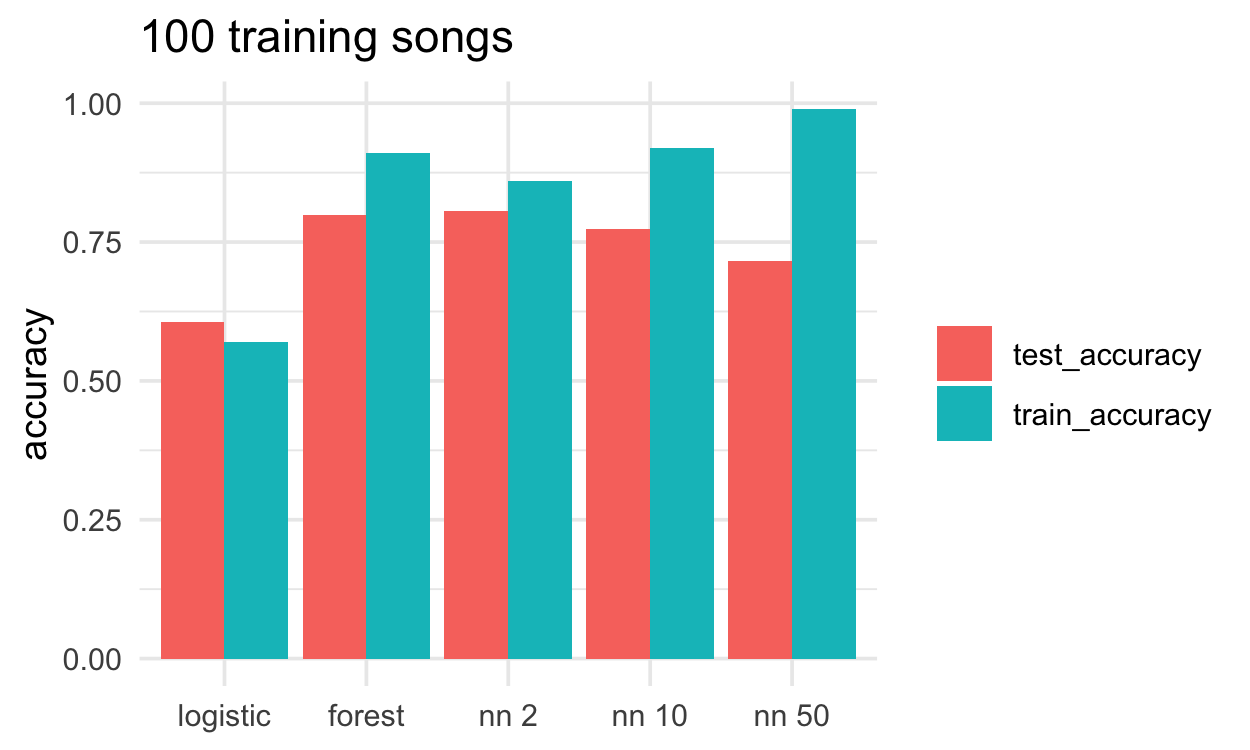

In [6]:
# Chart code goes here
results_small |>
    pivot_longer(c(train_accuracy, test_accuracy), names_to = 'data', values_to = 'accuracy') |>
    mutate(model = factor(model, levels = results_small$model)) |>
    ggplot(aes(x = model, y = accuracy, fill = data)) +
    geom_col(position = 'dodge') +
    labs(title = '100 training songs', x = NULL, y = 'accuracy', fill = NULL) +
    theme_minimal()

## 3. More data

Run `compare_models()` again, with all of `train` (about 5,500 songs).

In [7]:
results_all = compare_models(train)

results_all

         model    train_accuracy test_accuracy
logistic logistic 0.6033693      0.6023435    
forest   forest   0.9351767      0.8161845    
nn 2     nn 2     0.8090093      0.8149030    
nn 10    nn 10    0.8167002      0.8224094    
nn 50    nn 50    0.8320820      0.8125229    

**Check:** the nets should now be close to the forest, at about 0.82 on the test songs.

- Is `nn 50` still much worse than `nn 2`? Do more nodes help now?
- Logistic regression is stuck at about 0.60. Why? (Think about the stripe in the lecture 13 exercise.)

**Answers:**

- No. With about 5,500 songs, `nn 50` (about 0.81 on test) is about the same as `nn 2` (about 0.81), and `nn 10` is a little better (about 0.82). With enough data, more nodes no longer overfit, but they don't help much either.
- Logistic regression can only draw one straight line between EDM and rap. Many EDM songs sit in a narrow **stripe** of tempo, about 125 to 130 BPM, with rap songs above and below it. A single straight line can't separate a stripe, so logistic regression stays near 0.60.

## 4. Plot the results when using all the data

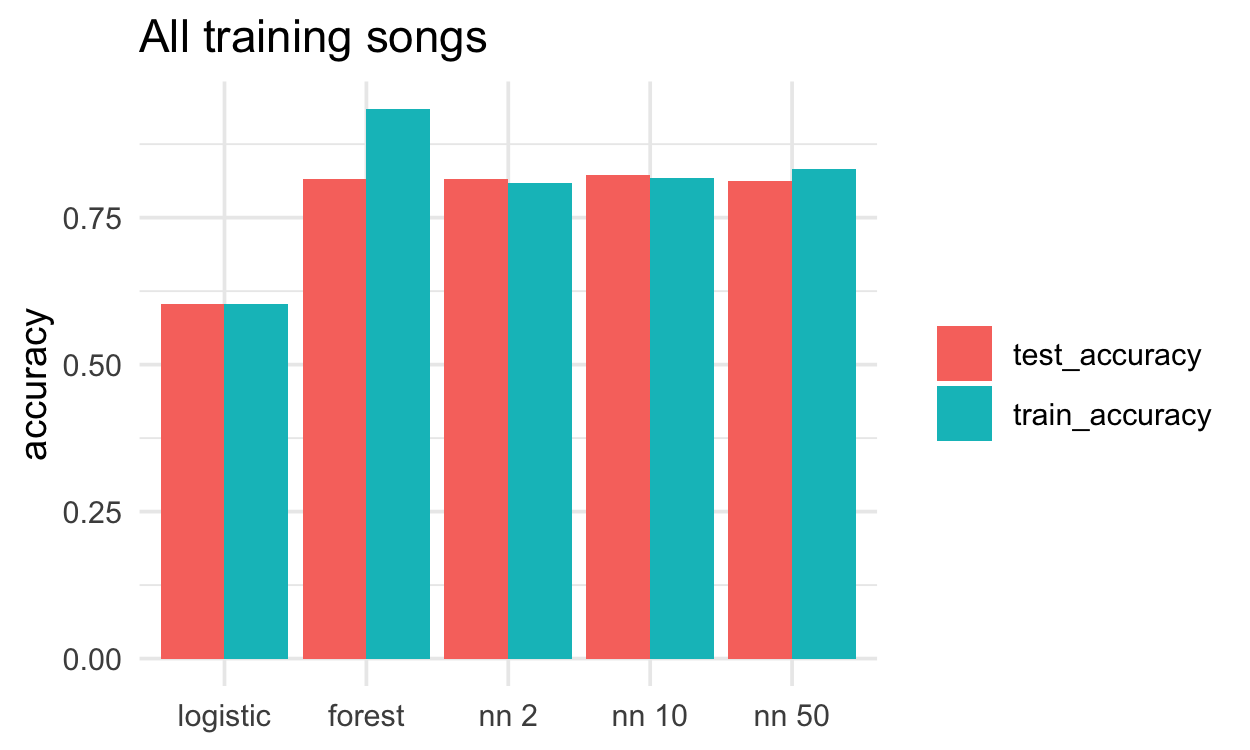

In [8]:
# Chart code goes here
results_all |>
    pivot_longer(c(train_accuracy, test_accuracy), names_to = 'data', values_to = 'accuracy') |>
    mutate(model = factor(model, levels = results_all$model)) |>
    ggplot(aes(x = model, y = accuracy, fill = data)) +
    geom_col(position = 'dodge') +
    labs(title = 'All training songs', x = NULL, y = 'accuracy', fill = NULL) +
    theme_minimal()

## 5. Which model?

You must pick one model for a new playlist with **100 labeled songs**. Which do you pick?

*Your answer:* I would pick the neural net with **2 hidden nodes** (`nn 2`). With 100 songs it had the best test accuracy (about 0.81), just above the random forest (about 0.80). Bigger nets overfit with so little data (`nn 50` fell to about 0.72 on test), and logistic regression can't draw the tempo stripe, so it stays near 0.60.